In [1]:
from pathlib import Path
import json, sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from utils.calculations import calculate_model, calculate_moscow_model, format_rub, format_mln
CONFIG=json.loads((ROOT/'data/task_05_cocomo_config.json').read_text(encoding='utf-8'))
base=calculate_model(CONFIG)
moscow=calculate_moscow_model(CONFIG)
task_opening=f"""# Экзаменационная задача №{CONFIG['task_id']}, {CONFIG['title']}

**Студент:** {CONFIG['student_name']}  
**Группа:** {CONFIG['group']}  
**Система:** {CONFIG['system_name']}  
**Метод оценки:** COCOMO II

Все исходные параметры загружаются из JSON. Расчёты выполняются ниже по формулам модели."""
display(Markdown(task_opening))

# Экзаменационная задача №5, Расчёт стоимости разработки по COCOMO II

**Студент:** Глазков Тимофей Владимирович  
**Группа:** БИ ОЗФО5-1  
**Система:** Единый портал поддержки предпринимателей  
**Метод оценки:** COCOMO II

Все исходные параметры загружаются из JSON. Расчёты выполняются ниже по формулам модели.

## Условие задачи

Необходимо рассчитать стоимость разработки государственной информационной системы **«Единый портал поддержки предпринимателей»** с использованием COCOMO II.

### Исходные данные

- размер системы — 450 функциональных точек;
- язык программирования — C#;
- коэффициент перевода — 54 строки на функциональную точку;
- повторное использование компонентов — 20%;
- заданы пять коэффициентов масштаба и пятнадцать множителей трудоёмкости;
- стоимость человеко-месяца — 220 000 руб.;
- накладные расходы — 25% от фонда оплаты труда;
- НДС — 20%.

### Требуется

1. Рассчитать KLOC с учётом повторного использования.
2. Рассчитать коэффициент масштаба B.
3. Рассчитать произведение множителей трудоёмкости EM.
4. Рассчитать трудоёмкость в человеко-месяцах.
5. Рассчитать длительность разработки.
6. Рассчитать прямые затраты.
7. Рассчитать накладные расходы.
8. Рассчитать стоимость без НДС.
9. Рассчитать стоимость с НДС.
10. Сравнить результат с ориентиром методики города Москвы и объяснить расхождения.

## Экономическая постановка

COCOMO II переводит технический масштаб проекта и его сложность в оценку трудоёмкости. Трудоёмкость показывает, сколько человеко-месяцев потребуется команде. Затем она переводится в деньги через стоимость одного человеко-месяца.

Логика расчёта: сначала определяется размер кода, затем учитываются масштаб проекта и факторы сложности, после чего оцениваются срок и бюджет.

## Шаг 1. Расчёт размера проекта

Сначала переводим функциональные точки в тысячи строк кода. Для COCOMO II затем вычитаем долю повторно используемых компонентов. В методике Москвы из лекции №19 повторное использование в формуле размера отдельно не вычитается, поэтому там остаётся полный размер 24,30 KLOC.

In [2]:
fp=CONFIG['functional_points']; kloc_factor=CONFIG['kloc_per_1000_fp']; reuse=CONFIG['reuse_fraction']
kloc_before=fp*kloc_factor/1000
print(f"До учёта повторного использования: {format_rub(kloc_before,2)} KLOC")
print(f"Повторно используется: {reuse*100:.0f}%")
print(f"KLOC после корректировки: {format_rub(base['kloc'],2)} KLOC")
display(pd.DataFrame({'Показатель':['Функциональные точки','Строк на FP','Размер без повторного использования','Доля повторного использования','Итоговый KLOC'],'Значение':[format_rub(fp),format_rub(kloc_factor),format_rub(kloc_before,2),f'{reuse*100:.0f}%'.replace('.',','),format_rub(base['kloc'],2)]}))

До учёта повторного использования: 24,30 KLOC
Повторно используется: 20%
KLOC после корректировки: 19,44 KLOC


,Показатель,Значение
0,Функциональные точки,450
1,Строк на FP,54
2,Размер без повторного использования,"24,30"
3,Доля повторного использования,20%
4,Итоговый KLOC,"19,44"


## Шаг 2. Коэффициент масштаба B

Пять коэффициентов масштаба отражают, насколько проект сложен с точки зрения прецедентности, гибкости, рисков, командной работы и зрелости процессов. Их сумма увеличивает базовый показатель B.

In [3]:
sf_table=pd.DataFrame({'Фактор':list(CONFIG['scale_factors'].keys()),'Значение':list(CONFIG['scale_factors'].values())})
display(sf_table)
print(f"Сумма коэффициентов масштаба: {format_rub(base['sum_sf'],2)}")
print(f"B = B_base + step × сумма SF = {CONFIG['cocomo']['B_base']:.2f} + {CONFIG['cocomo']['scale_step']:.2f} × {base['sum_sf']:.0f} = {base['B']:.2f}")

,Фактор,Значение
0,PREC,4
1,FLEX,3
2,RESL,3
3,TEAM,4
4,PMAT,3


Сумма коэффициентов масштаба: 17,00
B = B_base + step × сумма SF = 0.91 + 0.01 × 17 = 1.08


## Шаг 3. Произведение множителей трудоёмкости

Множители EM корректируют базовую трудоёмкость. Значение больше 1 увеличивает оценку, а значение меньше 1 уменьшает её. В данном проекте итоговый множитель рассчитывается как произведение всех пятнадцати факторов.

In [4]:
em=CONFIG['effort_multipliers']
em_table=pd.DataFrame({'Фактор':list(em.keys()),'Множитель':list(em.values()),'Используется':[(v != 0) for v in em.values()]})
display(em_table)
print(f"Используется факторов: {len(base['active_em'])} из {len(em)}")
print(f"Не используются из-за значения 0: {', '.join(base['inactive_em']) or 'нет'}")
print(f"Итоговое произведение активных EM: {format_rub(base['em_total'],3)}")

,Фактор,Множитель,Используется
0,RELY,1.15,True
1,DATA,1.00,True
2,CPLX,1.15,True
3,RUSE,1.10,True
4,DOCU,0.00,False
5,TIME,1.00,True
6,STOR,1.00,True
7,PVOL,0.00,False
8,ACAP,1.15,True
9,PCAP,1.10,True


Используется факторов: 15 из 17
Не используются из-за значения 0: DOCU, PVOL
Итоговое произведение активных EM: 1,840


## Шаг 4. Трудоёмкость

Формула COCOMO II: `Effort = A × KLOC^B × EM_total`. Результат выражается в человеко-месяцах. Это не количество календарных месяцев: несколько специалистов могут работать одновременно.

In [5]:
effort_table=pd.DataFrame({'Компонент':['A','KLOC','B','EM_total','Трудоёмкость'],'Значение':[CONFIG['cocomo']['A'],base['kloc'],base['B'],base['em_total'],base['effort_pm']],'Единица':['коэффициент','KLOC','коэффициент','коэффициент','чел.-мес.']})
# Не используем DataFrame.style: в JupyterLab Desktop иногда отсутствуют шаблоны Jinja.
effort_display=effort_table.copy()
effort_display['Значение']=effort_display['Значение'].map(lambda value: format_rub(value,3))
display(effort_display)
print(f"Трудоёмкость проекта: {format_rub(base['effort_pm'],1)} чел.-мес.")

,Компонент,Значение,Единица
0,A,"2,940",коэффициент
1,KLOC,"19,440",KLOC
2,B,"1,080",коэффициент
3,EM_total,"1,840",коэффициент
4,Трудоёмкость,"133,358",чел.-мес.


Трудоёмкость проекта: 133,4 чел.-мес.


## Шаг 5. Длительность разработки

Длительность рассчитывается отдельной формулой COCOMO II. Она растёт медленнее трудоёмкости, потому что увеличение команды частично сокращает календарный срок, но не пропорционально.

In [6]:
print(f"TDEV = {CONFIG['cocomo']['duration_coefficient']} × Effort^{CONFIG['cocomo']['duration_exponent']}")
print(f"Расчётная длительность: {format_rub(base['tdev_months'],1)} месяцев")

TDEV = 2.5 × Effort^0.35
Расчётная длительность: 13,9 месяцев


## Шаг 6. Стоимость разработки

Сначала трудоёмкость умножается на стоимость одного человеко-месяца. Затем добавляются накладные расходы. НДС начисляется на полную стоимость до НДС.

In [7]:
costs=pd.DataFrame({'Статья':['Прямые затраты','Накладные расходы','Стоимость без НДС','НДС','Стоимость с НДС'],'Сумма, руб.':[base['direct_cost_rub'],base['overhead_rub'],base['cost_before_vat_rub'],base['vat_rub'],base['total_cost_rub']]})
costs['Сумма, млн руб.']=costs['Сумма, руб.'].map(format_mln)
display(costs.drop(columns='Сумма, руб.'))
print(f"Итоговая стоимость с НДС: {format_mln(base['total_cost_rub'])} млн руб.")

,Статья,"Сумма, млн руб."
0,Прямые затраты,"29,3"
1,Накладные расходы,"7,3"
2,Стоимость без НДС,"36,7"
3,НДС,"7,3"
4,Стоимость с НДС,"44,0"


Итоговая стоимость с НДС: 44,0 млн руб.


## Часть 5. Сравнение с методикой города Москвы

В лекции №19 приведена самостоятельная нормативная модель расчёта стоимости информационной системы. Она использует размер `РР` (тысячи строк условного кода), семь коэффициентов трудоёмкости `МТ1–МТ7`, плановую продолжительность, структуру исполнителей, зарплатную базу, коэффициент пересчёта, рентабельность и коэффициент квалификации.

Часть параметров в условии задачи 5 отсутствует. Поэтому они вынесены в JSON как явные допущения: значение каждого МТ-фактора, 14 месяцев плановой длительности, `Кпер = 1,00`, рентабельность 10% и индекс старшего аналитика, принятый равным индексу аналитика/разработчика. Это не скрытые данные, а отдельный воспроизводимый сценарий сравнения. Базовый коэффициент пересчёта `Кпер = 1,064` взят из лекции №17. В базовом сценарии используется `Р = 5%`, как в её примере; значение `Р = 10%` из диапазона лекции №19 рассматривается как верхняя граница, а не как базовое значение.

In [8]:
m=CONFIG['moscow_comparison']
mt_table=pd.DataFrame({'Фактор':list(m['mt_factors'].keys()),'Значение':list(m['mt_factors'].values()),'Зачем нужен':[
'Надёжность государственной системы','Размер тестовой базы данных','Количество интеграций','Сложность системы','Мобильная версия','Частота обновлений платформы','Новизна системы']})
display(mt_table)
# Показываем только содержательные поля; служебный флаг index_assumption не является экономическим показателем.
roles_table=pd.DataFrame([{
    'Должность':role['name'],
    'Коэффициент численности Кч':role['headcount_coefficient'],
    'Индекс зарплаты И':role['salary_index']
} for role in m['roles']])
display(roles_table)
comparison=pd.DataFrame({'Показатель':['Размер системы','Произведение МТ','Трудоёмкость','Плановая длительность','Расчётная численность','Коэффициент квалификации','Стоимость без НДС','НДС','Стоимость с НДС'],
'COCOMO II':[f"{base['kloc']:.2f} KLOC",'—',f"{base['effort_pm']:.1f} чел.-мес.",f"{base['tdev_months']:.1f} мес.",'—','—',format_mln(base['cost_before_vat_rub'])+' млн руб.',format_mln(base['vat_rub'])+' млн руб.',format_mln(base['total_cost_rub'])+' млн руб.'],
'Методика Москвы':[f"{moscow['size_kloc']:.2f} РР",f"{moscow['mt_product']:.4f}",f"{moscow['effort_pm']:.1f} чел.-мес.",f"{moscow['planned_duration_months']:.0f} мес.",f"{moscow['headcount']:.1f} чел.",f"{moscow['qualification_coefficient']:.3f}",format_mln(moscow['cost_before_vat_rub'])+' млн руб.',format_mln(moscow['vat_rub'])+' млн руб.',format_mln(moscow['total_cost_rub'])+' млн руб.']})
display(comparison)
print('Обозначения размера: KLOC — тысячи строк кода в COCOMO II; РР — размер системы в тысячах строк условного кода по методике Москвы. Численно единицы сопоставимы, но обозначения моделей сохраняются раздельно.')
print('Объяснение допущений:')
for key,value in m['notes'].items(): print(f'- {key}: {value}')
print(f"Разница в трудоёмкости Москвы относительно COCOMO II: {(moscow['effort_pm']/base['effort_pm']-1)*100:.1f}%")
print(f"Разница в стоимости с НДС Москвы относительно COCOMO II: {(moscow['total_cost_rub']/base['total_cost_rub']-1)*100:.1f}%")
print(f"Базовые параметры НМЦК: Кпер = {m['conversion_coefficient']:.3f}; рентабельность = {m['profitability_rate']*100:.0f}%; К3 = {m['salary_share_coefficient']:.2f}.")
# Верхний сценарий по рентабельности из лекции №19
upper_cfg=json.loads(json.dumps(CONFIG)); upper_cfg['moscow_comparison']['profitability_rate']=max(m['profitability_rate_values'])
upper=calculate_moscow_model(upper_cfg)
profitability_table=pd.DataFrame({'Сценарий':['Базовый — Р = 5%','Верхний — Р = 10%'],'Рентабельность':[f"{m['profitability_rate']*100:.0f}%",f"{max(m['profitability_rate_values'])*100:.0f}%"],'НМЦК без НДС, млн руб.':[format_mln(moscow['cost_before_vat_rub']),format_mln(upper['cost_before_vat_rub'])],'НМЦК с НДС, млн руб.':[format_mln(moscow['total_cost_rub']),format_mln(upper['total_cost_rub'])]})
display(profitability_table)

,Фактор,Значение,Зачем нужен
0,MT1_reliability,1.15,Надёжность государственной системы
1,MT2_test_database,1.00,Размер тестовой базы данных
2,MT3_integrations,1.00,Количество интеграций
3,MT4_complexity,1.15,Сложность системы
4,MT5_mobile,1.00,Мобильная версия
5,MT6_updates,1.00,Частота обновлений платформы
6,MT7_novelty,1.04,Новизна системы


,Должность,Коэффициент численности Кч,Индекс зарплаты И
0,Заместитель руководителя,0.058,1.85
1,Главный архитектор,0.058,1.70
2,Архитектор/методолог,0.231,1.40
3,Старший аналитик,0.058,0.90
4,Аналитик/разработчик,0.520,0.90
5,Тестировщик,0.173,0.75


,Показатель,COCOMO II,Методика Москвы
0,Размер системы,19.44 KLOC,24.30 РР
1,Произведение МТ,—,1.3754
2,Трудоёмкость,133.4 чел.-мес.,142.7 чел.-мес.
3,Плановая длительность,13.9 мес.,14 мес.
4,Расчётная численность,—,11.2 чел.
5,Коэффициент квалификации,—,1.074
6,Стоимость без НДС,"36,7 млн руб.","22,6 млн руб."
7,НДС,"7,3 млн руб.","4,5 млн руб."
8,Стоимость с НДС,"44,0 млн руб.","27,2 млн руб."


Обозначения размера: KLOC — тысячи строк кода в COCOMO II; РР — размер системы в тысячах строк условного кода по методике Москвы. Численно единицы сопоставимы, но обозначения моделей сохраняются раздельно.
Объяснение допущений:
- mt_factors: MT1–MT7 не приведены в условии задачи 5; значения приняты по характеристикам государственной информационной системы и вынесены в JSON.
- duration: 14 месяцев округлены от расчётной длительности COCOMO II для соблюдения диапазона ОТр/Тп из лекции №19.
- conversion: Кпер = 1,064 взят из расчётного примера формирования НМЦК в лекции №17; он переводит базовую зарплату в текущий ценовой уровень.
- senior_analyst_index: Для старшего аналитика использован индекс аналитика/разработчика 0,90, так как отдельный индекс в таблице лекции не указан.
- project_manager: Руководитель проекта назначается отдельно и не включён в коэффициент численности, поскольку в лекции его Кч указан как 0,0.
- profitability: Базовый сценарий использует Р = 5%, как в примере лекции

,Сценарий,Рентабельность,"НМЦК без НДС, млн руб.","НМЦК с НДС, млн руб."
0,Базовый — Р = 5%,5%,"22,6","27,2"
1,Верхний — Р = 10%,10%,"23,7","28,5"


## Анализ чувствительности

Чувствительность показывает, какие параметры сильнее всего влияют на бюджет. Это полезно для планирования: можно понять, что важнее уточнять на этапе подготовки сметы — повторное использование, стоимость команды или оценку сложности.

In [9]:
reuse_rows=[]
for r in CONFIG['sensitivity']['reuse_fraction_values']:
 x=calculate_model(CONFIG,reuse_fraction=r); reuse_rows.append({'Повторное использование, %':r*100,'KLOC':x['kloc'],'Трудоёмкость, чел.-мес.':x['effort_pm'],'Стоимость с НДС, млн руб.':x['total_cost_rub']/1e6})
reuse_df=pd.DataFrame(reuse_rows); reuse_display=reuse_df.copy(); reuse_display['Повторное использование, %']=reuse_display['Повторное использование, %'].map(lambda x:f'{x:.0f}%'); reuse_display['KLOC']=reuse_display['KLOC'].map(lambda x:format_rub(x,2)); reuse_display['Трудоёмкость, чел.-мес.']=reuse_display['Трудоёмкость, чел.-мес.'].map(lambda x:format_rub(x,1)); reuse_display['Стоимость с НДС, млн руб.']=reuse_display['Стоимость с НДС, млн руб.'].map(format_rub); display(reuse_display)

,"Повторное использование, %",KLOC,"Трудоёмкость, чел.-мес.","Стоимость с НДС, млн руб."
0,0%,"24,30","169,7",56
1,10%,"21,87","151,4",50
2,20%,"19,44","133,4",44
3,30%,"17,01","115,4",38
4,40%,"14,58","97,7",32


In [10]:
rate_rows=[]
for rate in CONFIG['sensitivity']['cost_per_person_month_values']:
 x=calculate_model(CONFIG,cost_per_person_month=rate); rate_rows.append({'Стоимость чел.-мес., руб.':rate,'Стоимость с НДС, млн руб.':x['total_cost_rub']/1e6})
rate_df=pd.DataFrame(rate_rows); rate_display=rate_df.copy(); rate_display['Стоимость чел.-мес., руб.']=rate_display['Стоимость чел.-мес., руб.'].map(format_rub); rate_display['Стоимость с НДС, млн руб.']=rate_display['Стоимость с НДС, млн руб.'].map(format_rub); display(rate_display)

,"Стоимость чел.-мес., руб.","Стоимость с НДС, млн руб."
0,180 000,36
1,220 000,44
2,260 000,52
3,300 000,60


In [11]:
mult_rows=[]
for mult in CONFIG['sensitivity']['multiplier_scale_values']:
 x=calculate_model(CONFIG,multiplier_scale=mult); mult_rows.append({'Масштаб EM':mult,'Трудоёмкость, чел.-мес.':x['effort_pm'],'Стоимость с НДС, млн руб.':x['total_cost_rub']/1e6})
mult_df=pd.DataFrame(mult_rows); mult_display=mult_df.copy(); mult_display['Масштаб EM']=mult_display['Масштаб EM'].map(lambda x:f'{x:.2f}'.replace('.',',')); mult_display['Трудоёмкость, чел.-мес.']=mult_display['Трудоёмкость, чел.-мес.'].map(lambda x:format_rub(x,1)); mult_display['Стоимость с НДС, млн руб.']=mult_display['Стоимость с НДС, млн руб.'].map(format_rub); display(mult_display)

,Масштаб EM,"Трудоёмкость, чел.-мес.","Стоимость с НДС, млн руб."
0,"0,90","120,0",40
1,"1,00","133,4",44
2,"1,10","146,7",48


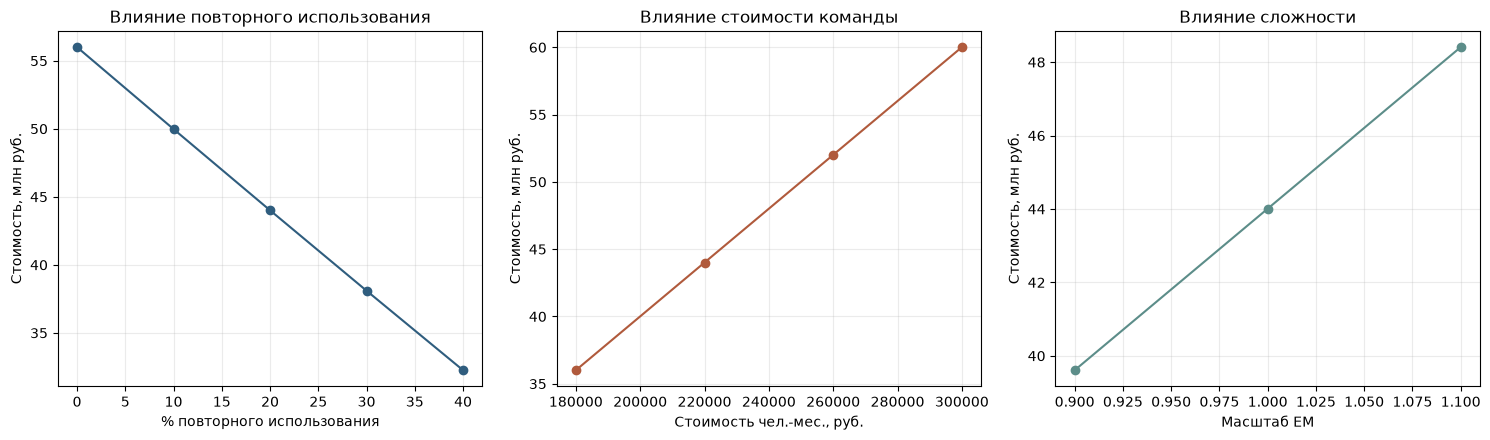

In [12]:
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
axes[0].plot(reuse_df['Повторное использование, %'],reuse_df['Стоимость с НДС, млн руб.'],marker='o',color='#2F5D7E'); axes[0].set_title('Влияние повторного использования'); axes[0].set_xlabel('% повторного использования'); axes[0].set_ylabel('Стоимость, млн руб.'); axes[0].grid(alpha=.25)
axes[1].plot(rate_df['Стоимость чел.-мес., руб.'],rate_df['Стоимость с НДС, млн руб.'],marker='o',color='#B05A3C'); axes[1].set_title('Влияние стоимости команды'); axes[1].set_xlabel('Стоимость чел.-мес., руб.'); axes[1].set_ylabel('Стоимость, млн руб.'); axes[1].grid(alpha=.25)
axes[2].plot(mult_df['Масштаб EM'],mult_df['Стоимость с НДС, млн руб.'],marker='o',color='#5C8D89'); axes[2].set_title('Влияние сложности'); axes[2].set_xlabel('Масштаб EM'); axes[2].set_ylabel('Стоимость, млн руб.'); axes[2].grid(alpha=.25)
fig.tight_layout(); fig.savefig(ROOT/'reports/figures/task_05_sensitivity.png',dpi=180,bbox_inches='tight'); plt.show()

## Итоговый вывод

В базовом сценарии COCOMO II даёт стоимость разработки около 44,0 млн руб. с НДС, а методика города Москвы — около 27,2 млн руб. с НДС. Московская оценка рассчитана с параметрами из лекции №17 (`ЗПсредняя = 78 300 руб.`, `Кпер = 1,064`, `К3 = 0,65`, `Р = 5%`) и структурой трудоёмкости из лекции №19.

Рентабельность 10% показана отдельно как верхний сценарий лекции №19. Поэтому базовая цифра не смешивает данные разных примеров. Разница между моделями объясняется разными формулами, размером и разными правилами учёта повторного использования, коэффициентами факторов, структурой команды и стоимостной базой.

Лекции №7 и №8 не включены в численный расчёт: для TCO, ROI и NPV в условии нет эксплуатационных затрат, выгод и денежных потоков.

In [13]:
print(f"COCOMO II: {format_rub(base['effort_pm'],1)} чел.-мес.; {format_mln(base['total_cost_rub'])} млн руб. с НДС.")
print(f"Москва, базовый сценарий Р = {m['profitability_rate']*100:.0f}%: {format_rub(moscow['effort_pm'],1)} чел.-мес.; {format_mln(moscow['total_cost_rub'])} млн руб. с НДС.")
print(f"Москва, верхний сценарий Р = {max(m['profitability_rate_values'])*100:.0f}%: {format_mln(upper['total_cost_rub'])} млн руб. с НДС.")
print(f"Разница базовой стоимости Москвы относительно COCOMO II: {(moscow['total_cost_rub']/base['total_cost_rub']-1)*100:.1f}%.")
print('Рекомендация: подтвердить МТ1–МТ7, дату коэффициента Кпер, плановую длительность и состав исполнителей перед утверждением НМЦК.')

COCOMO II: 133,4 чел.-мес.; 44,0 млн руб. с НДС.
Москва, базовый сценарий Р = 5%: 142,7 чел.-мес.; 27,2 млн руб. с НДС.
Москва, верхний сценарий Р = 10%: 28,5 млн руб. с НДС.
Разница базовой стоимости Москвы относительно COCOMO II: -38.3%.
Рекомендация: подтвердить МТ1–МТ7, дату коэффициента Кпер, плановую длительность и состав исполнителей перед утверждением НМЦК.


In [14]:
%%capture
# Экспорт выполненного Notebook в HTML-отчёт
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_05_report task_05_cocomo_ii.ipynb